In [1]:
import os
import json
import numpy as np
import pandas as pd
import sqlite3
from astropy.cosmology import FlatLambdaCDM
import astropy.units as u
from astropy.constants import G, c, M_sun

import matplotlib.pyplot as plt

In [2]:
## Cosmological model
H0 = 70.0 # in km s^-1 Mpc^-1
Om0 = 0.3 # Omega matter at t=t_0 (now)
cosmo = FlatLambdaCDM(H0=H0 * u.km / u.s / u.Mpc, Om0=Om0)
r_H = cosmo.hubble_distance
h = cosmo.h

In [3]:
## load map database
path_to_db = '/mnt/d/data/magnification_maps/masterlist.db'
db = sqlite3.connect(path_to_db)
## select maps
df = pd.read_sql_query("SELECT * FROM maps WHERE 1/((1-kappa)*(1-kappa) - gamma*gamma) > 0 AND kappa < 1.0", db)
df = df.drop(df[df['kappa']==0.0].index)

In [4]:
# df = df.head(n=1)
# df

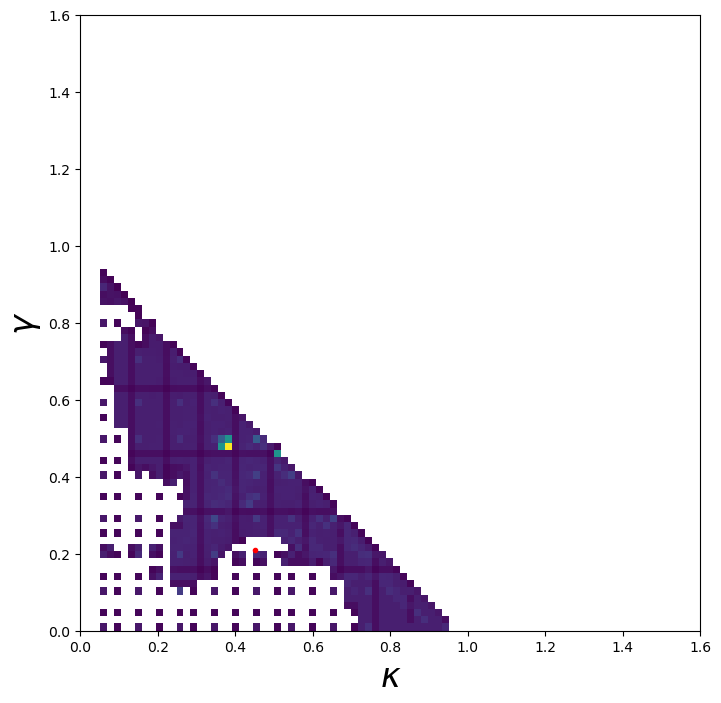

In [5]:
fig, ax = plt.subplots(1, 1, figsize=(8, 8))

ax.hist2d(df['kappa'], df['gamma'], bins=50, cmin=1, cmax=5000)
ax.scatter(0.45, 0.21, marker='.', color='r')

ax.set_xlabel('$\kappa$', fontsize=24)
ax.set_ylabel('$\gamma$', fontsize=24)
ax.set_xlim(0, 1.6)
ax.set_ylim(0, 1.6);

In [6]:
## create list of dictionaries for each map
maps = []
for index, row in df.iterrows():
    maps.append({"id":int(row['id']),
                "kappa":row['kappa'],
                "gamma":row['gamma'],
                "s":row['s'],
                "mass":1.0,
                "gamma_angle":0.0})
len(maps)

32697

In [12]:
np.savetxt('mapids.txt', df['id'].values, fmt='%d')

In [14]:
## system parameters
M = 1*M_sun
zl = 0.5
zs = 2
Dl  = cosmo.angular_diameter_distance(zl)
Ds  = cosmo.angular_diameter_distance(zs)
Dls = cosmo.angular_diameter_distance_z1z2(zl, zs)
RE_s = ((4*G*M/c**2) * (Ds*Dls/Dl))**0.5

disc_sizes = np.linspace(1, 400, 134)/400
disc_sizes

array([0.0025, 0.01  , 0.0175, 0.025 , 0.0325, 0.04  , 0.0475, 0.055 ,
       0.0625, 0.07  , 0.0775, 0.085 , 0.0925, 0.1   , 0.1075, 0.115 ,
       0.1225, 0.13  , 0.1375, 0.145 , 0.1525, 0.16  , 0.1675, 0.175 ,
       0.1825, 0.19  , 0.1975, 0.205 , 0.2125, 0.22  , 0.2275, 0.235 ,
       0.2425, 0.25  , 0.2575, 0.265 , 0.2725, 0.28  , 0.2875, 0.295 ,
       0.3025, 0.31  , 0.3175, 0.325 , 0.3325, 0.34  , 0.3475, 0.355 ,
       0.3625, 0.37  , 0.3775, 0.385 , 0.3925, 0.4   , 0.4075, 0.415 ,
       0.4225, 0.43  , 0.4375, 0.445 , 0.4525, 0.46  , 0.4675, 0.475 ,
       0.4825, 0.49  , 0.4975, 0.505 , 0.5125, 0.52  , 0.5275, 0.535 ,
       0.5425, 0.55  , 0.5575, 0.565 , 0.5725, 0.58  , 0.5875, 0.595 ,
       0.6025, 0.61  , 0.6175, 0.625 , 0.6325, 0.64  , 0.6475, 0.655 ,
       0.6625, 0.67  , 0.6775, 0.685 , 0.6925, 0.7   , 0.7075, 0.715 ,
       0.7225, 0.73  , 0.7375, 0.745 , 0.7525, 0.76  , 0.7675, 0.775 ,
       0.7825, 0.79  , 0.7975, 0.805 , 0.8125, 0.82  , 0.8275, 0.835 ,
      

In [21]:
df[df['id']==92050]

,index,id,kappa,gamma,s
1181,2827,92050,0.46,0.51,0.95


In [19]:
## Open base template
with open('input_cpp.json') as json_input:
    myinput = json.load(json_input)

for i in range(len(maps)):
    ## set the parameters
    myinput['profile']['r0'] = 400#RE_s.decompose().to(u.cm).value * 10e-14
    myinput['lrest'] = disc_sizes.tolist()
    #myinput['sizes'] = [str(int(i*10)).zfill(2) for i in disc_sizes]
    myinput['maps'] = [maps[i]]

    myinput['system']['zl'] = zl
    myinput['system']['zs'] = zs
    myinput['system']['Dl'] = 1
    myinput['system']['Ds'] = 1
    myinput['system']['Dls'] = 877.9149519890261


    with open('/mnt/d/data/imf_with_doubles/convolved/'+str(maps[i]['id'])+'.json', 'w') as outfile:
        json.dump(myinput, outfile, indent=4, separators=(',', ':'))

In [20]:
# ## Open base template
# with open('input_cpp.json') as json_input:
#     myinput = json.load(json_input)

# ## set the parameters
# myinput['profile']['r0'] = 400#RE_s.decompose().to(u.cm).value * 10e-14
# myinput['lrest'] = disc_sizes.tolist()
# #myinput['sizes'] = [str(int(i*10)).zfill(2) for i in disc_sizes]
# myinput['maps'] = maps

# myinput['system']['zl'] = zl
# myinput['system']['zs'] = zs
# myinput['system']['Dl'] = 1
# myinput['system']['Ds'] = 1
# myinput['system']['Dls'] = 877.9149519890261


# with open('/mnt/d/data/imf_with_doubles/convolved/input_cpp.json', 'w') as outfile:
#     json.dump(myinput, outfile, indent=4, separators=(',', ':'))

In [27]:
len(maps)

32697